# Exercise Lecture 3 — Arbitrage-free implied volatility and temporal filtering
**MTH 9871 · Beat Ammon · Part 1 + Part 2(A)**

**Data:** `NVDA_20241014.parquet`, a full trading day of one-minute OPRA-style NVDA option snapshots (390 minutes, 09:31–16:00 ET). We use the short-dated 2024-11-15 expiry and infer the forward independently at every minute from robust call–put parity across near-ATM strikes. To reduce early-exercise and stale-deep-ITM effects, the fit uses OTM puts (converted to call-equivalent prices) below the forward and OTM calls above it.

**Extension chosen: A — temporal smoothing.** A constrained Kalman projection reduces snapshot noise while retaining the same static-arbitrage and endogenous Roger Lee constraints as the raw fits. It directly addresses quote stability for a market maker and admits the required slack-constraint validation against the textbook Kalman posterior.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import minimize, brentq
from scipy.stats import norm
from statsmodels.tsa.stattools import acf
from pathlib import Path

np.set_printoptions(precision=6, suppress=True)
DATA_PATH = Path("NVDA_20241014.parquet")
TICKER = "NVDA"
EXPIRY = pd.Timestamp("2024-11-15")
VALUATION_TIME = pd.Timestamp("2024-10-14 09:31:00")
EXPIRY_TIME = EXPIRY + pd.Timedelta(hours=16)
R = 0.048  # short-dated USD continuously compounded proxy
Q = 0.0    # forward is inferred from parity, so q is not imposed on the fit
TAU = (EXPIRY_TIME - VALUATION_TIME).total_seconds() / (365.0 * 24 * 3600)
DF = np.exp(-R * TAU)
S0 = 137.15
assert DATA_PATH.exists(), f"Missing input file: {DATA_PATH}"
print(f"Selected {TICKER} {EXPIRY.date()} expiry | tau={TAU:.6f} years | DF={DF:.6f}")

Selected NVDA 2024-11-15 expiry | tau=0.088411 years | DF=0.995765


## 1. Black–Scholes pricing and inversion
We use a European Black–Scholes forward pricer and Brent inversion. The recovery test below checks price → implied vol → price at machine-level accuracy before any market fitting. The short expiry limits rate sensitivity. Because NVDA equity options are American, we use OTM options and parity-implied forwards to reduce (but not eliminate) early-exercise and dividend-model effects.

In [2]:
def bs_call(F, K, tau, vol, df=1.0):
    vol = np.asarray(vol); K = np.asarray(K)
    d1 = (np.log(F / K) + 0.5 * vol**2 * tau) / (vol * np.sqrt(tau))
    d2 = d1 - vol * np.sqrt(tau)
    return df * (F * norm.cdf(d1) - K * norm.cdf(d2))

def bs_put(F, K, tau, vol, df=1.0):
    return bs_call(F, K, tau, vol, df) - df * (F - K)

def implied_vol(price, F, K, tau, df=1.0):
    intrinsic = df * max(F - K, 0.0)
    if not intrinsic < price < df * F:
        return np.nan
    return brentq(lambda v: float(bs_call(F, K, tau, v, df) - price), 1e-5, 5.0, xtol=1e-11)

F_TEST = S0 * np.exp(R * TAU)
for v in [0.25, 0.50, 0.85]:
    for k in [120.0, 137.0, 155.0]:
        p = float(bs_call(F_TEST, k, TAU, v, DF))
        v2 = implied_vol(p, F_TEST, k, TAU, DF)
        assert abs(v - v2) < 1e-7
        assert abs(float(bs_call(F_TEST, k, TAU, v2, DF)) - p) < 1e-9
print("Black–Scholes price → implied vol → price recovery: PASS")

Black–Scholes price → implied vol → price recovery: PASS


## 2. Endpoint slope: derive it in SNS coordinates
Let $k=\log(K/F)$, $\omega(k)=\tau\sigma(k)^2$, $a=\sigma_{ATM}=\sigma(0)$, and $s=k/(a\sqrt\tau)$. The fitted curve is **annualized variance** $v(s)=\sigma(s)^2$, so
$$\frac{\partial\omega}{\partial k}=\tau\frac{\partial v}{\partial s}\frac{1}{a\sqrt\tau}=\frac{\sqrt\tau}{a}v'(s).$$
Hence Lee's asymptotic wing-slope bound $|\partial_k\omega|\le2$ becomes
$$\boxed{|v'(s)|\le 2a/\sqrt\tau},\qquad a=\sqrt{v(0)}.$$
For **total variance** $\omega(s)$ the bound instead reads $|\omega'(s)|\le2a\sqrt\tau$. These are not interchangeable. More precisely, Lee's formula gives individual left/right limiting slopes and the upper bound 2; the absolute-value bound is a conservative symmetric constraint.

**No external bootstrap:** $a=\sqrt{v(0)}$ depends on the coefficients. Writing $|D\beta|\le (2/\sqrt\tau)\sqrt{B(0)\beta}$ gives a convex feasible set: $|D\beta|^2\le (4/\tau) B(0)\beta$ (a rotated second-order cone, with $B(0)\beta\ge0$). We implement its differentiable inequality equivalent. We enforce it on the full fitting interval, which is stronger than Lee's asymptotic requirement.

## 3. A constrained low-dimensional variance curve
Use $v(s)=\beta_0+\beta_1s+\beta_2s^2+\beta_3s^3+\beta_4s^4$ on $s\in[-3.5,3.5]$. This is a local smile, not a global wing extrapolation. At every objective evaluation, $a=\sqrt{\beta_0}$ makes the observed SNS coordinates self-consistent with the fitted ATM volatility. The optimizer enforces positive variance, the endogenous Lee slope bound, and actual call-price monotonicity/convexity. A feasible warm start is retained if SLSQP proposes an infeasible point; the notebook reports how often this occurs rather than silently treating a failed optimizer as a successful refit.

In [3]:
def basis(s):
    s = np.asarray(s)
    return np.stack([s**j for j in range(5)], axis=-1)

def dbasis(s):
    s = np.asarray(s)
    return np.stack([np.zeros_like(s)] + [j * s**(j-1) for j in range(1, 5)], axis=-1)

def variance(beta, s):
    return basis(s) @ beta

def smile_prices(beta, F, K, tau, df=1.0):
    atm = np.sqrt(beta[0])
    s = np.log(np.asarray(K) / F) / (atm * np.sqrt(tau))
    return bs_call(F, K, tau, np.sqrt(np.maximum(variance(beta, s), 1e-12)), df)

def constraints(beta, F, tau, grid_size=51):
    a = np.sqrt(max(beta[0], 1e-12))
    sg = np.linspace(-3.5, 3.5, grid_size)
    K = F * np.exp(sg * a * np.sqrt(tau))
    v = variance(beta, sg)
    deriv = dbasis(sg) @ beta
    p = smile_prices(beta, F, K, tau, 1.0)
    slopes = np.diff(p) / np.diff(K)
    return np.r_[v - 0.0004, 4 * beta[0] / tau - deriv**2,
                 slopes + 1.0, -slopes, np.diff(slopes)]

DEFAULT_BETA = np.array([0.50**2, -0.020, 0.004, 0.0, 0.0])

def fit_curve(K, mid, F, tau, initial=None):
    initial = DEFAULT_BETA.copy() if initial is None else np.asarray(initial).copy()
    iv = np.array([implied_vol(p, F, k, tau, DF) for p, k in zip(mid, K)])
    ref_atm = np.sqrt(max(initial[0], 0.04))
    s0 = np.log(K / F) / (ref_atm * np.sqrt(tau))
    mask = np.isfinite(iv) & (np.abs(s0) <= 3.7)
    K, iv = K[mask], iv[mask]
    if len(K) < 8:
        raise RuntimeError(f"Only {len(K)} usable quotes in snapshot")

    def loss(b):
        a = np.sqrt(max(b[0], 1e-8))
        s = np.log(K / F) / (a * np.sqrt(tau))
        weights = 1.0 / (1.0 + 0.20 * s**2)
        residual = variance(b, s) - iv**2
        return 1e4 * np.average(residual**2, weights=weights) + 1e-5 * np.sum(b[1:]**2)

    out = minimize(loss, initial, method="SLSQP",
        bounds=[(0.02, 1.50)] + [(-2.0, 2.0)] * 4,
        constraints=[{"type": "ineq", "fun": lambda b: constraints(b, F, tau)}],
        options={"maxiter": 180, "ftol": 1e-10})
    candidates = [out.x, initial, DEFAULT_BETA]
    feasible = [b for b in candidates if np.min(constraints(b, F, tau)) >= -1e-6]
    if not feasible:
        raise RuntimeError("No feasible smile available")
    beta = min(feasible, key=loss)
    accepted = beta is out.x
    return beta, out, accepted, len(K)

## 4. OPRA input adapter and market-data choices
The Parquet stores `root, expiration, quote_datetime, strike, option_type` in its index and quote fields in columns. We select NVDA 2024-11-15 for all 390 minutes. At each minute, the forward is the median of $K+(C-P)/DF$ over valid paired quotes within 20% of spot. Below that forward we use OTM puts converted to synthetic calls via $C=P+DF(F-K)$; above it we use OTM calls. This avoids fitting noisy deep-ITM prices while preserving a single call-price curve. Quotes must be uncrossed, finite, inside the Black–Scholes no-arbitrage bounds, and within approximately four SNS under a 50% reference volatility.

In [4]:
raw = pd.read_parquet(DATA_PATH).reset_index()
raw["expiration"] = pd.to_datetime(raw["expiration"])
raw["quote_datetime"] = pd.to_datetime(raw["quote_datetime"])
raw = raw[(raw.root == TICKER) & (raw.expiration == EXPIRY)].copy()
raw["spot"] = (raw.underlying_bid + raw.underlying_ask) / 2
raw["mid"] = (raw.bid + raw.ask) / 2
raw = raw[np.isfinite(raw[["bid", "ask", "spot", "strike"]]).all(axis=1)]
raw = raw[(raw.ask > raw.bid) & (raw.bid >= 0) & (raw.spot > 0)]

rows, forward_rows = [], []
for ts, g in raw.groupby("quote_datetime", sort=True):
    spot = float(g.spot.median())
    piv = g.pivot_table(index="strike", columns="option_type", values="mid", aggfunc="median")
    paired = piv.dropna(subset=["C", "P"]).copy()
    paired = paired[(paired.index >= 0.8 * spot) & (paired.index <= 1.2 * spot)]
    f_candidates = paired.index.to_numpy(float) + (paired.C - paired.P).to_numpy(float) / DF
    f_candidates = f_candidates[np.isfinite(f_candidates) & (np.abs(np.log(f_candidates / spot)) < 0.06)]
    if len(f_candidates) < 5:
        continue
    F = float(np.median(f_candidates))
    forward_rows.append((ts, spot, F, len(f_candidates)))
    for strike, kg in g.groupby("strike"):
        kind = "P" if strike < F else "C"
        side = kg[kg.option_type == kind]
        if side.empty:
            continue
        q = side.iloc[0]
        adjustment = DF * (F - strike) if kind == "P" else 0.0
        bid, ask = float(q.bid + adjustment), float(q.ask + adjustment)
        mid = 0.5 * (bid + ask)
        intrinsic = DF * max(F - strike, 0.0)
        sns_ref = np.log(strike / F) / (0.50 * np.sqrt(TAU))
        if ask > bid and mid > intrinsic + 1e-5 and mid < DF * F and abs(sns_ref) <= 4.0:
            rows.append((ts, TICKER, EXPIRY, float(strike), bid, ask, mid, spot, F, kind))

quotes = pd.DataFrame(rows, columns=["timestamp", "underlying", "expiry", "strike",
                                      "bid", "ask", "mid", "spot", "forward", "source_type"])
forwards = pd.DataFrame(forward_rows, columns=["timestamp", "spot", "forward", "parity_pairs"])
SOURCE = f"REAL OPRA-STYLE {TICKER} {EXPIRY.date()}"
counts = quotes.groupby("timestamp").size()
assert quotes.timestamp.nunique() == 390, "Expected the full 390-minute trading day"
assert counts.min() >= 8, "Every minute needs at least eight usable strikes"
print(SOURCE)
print(f"Raw selected rows: {len(raw):,} | fitted quotes: {len(quotes):,} | snapshots: {quotes.timestamp.nunique()}")
print(f"Usable strikes/minute: min={counts.min()}, median={counts.median():.0f}, max={counts.max()}")
print(f"Parity pairs/minute: median={forwards.parity_pairs.median():.0f} | forward range={forwards.forward.min():.3f}–{forwards.forward.max():.3f}")

REAL OPRA-STYLE NVDA 2024-11-15
Raw selected rows: 176,280 | fitted quotes: 52,205 | snapshots: 390
Usable strikes/minute: min=133, median=134, max=134
Parity pairs/minute: median=45 | forward range=137.769–140.099


## 5. Fit all 390 one-minute snapshots, validate static arbitrage, and plot a representative smile

Fitted 50/390 snapshots


Fitted 100/390 snapshots


Fitted 150/390 snapshots


Fitted 200/390 snapshots


Fitted 250/390 snapshots


Fitted 300/390 snapshots


Fitted 350/390 snapshots


Fitted 390 snapshots | optimizer accepted: 390/390 | dense-grid minimum constraint: 4.168e-05


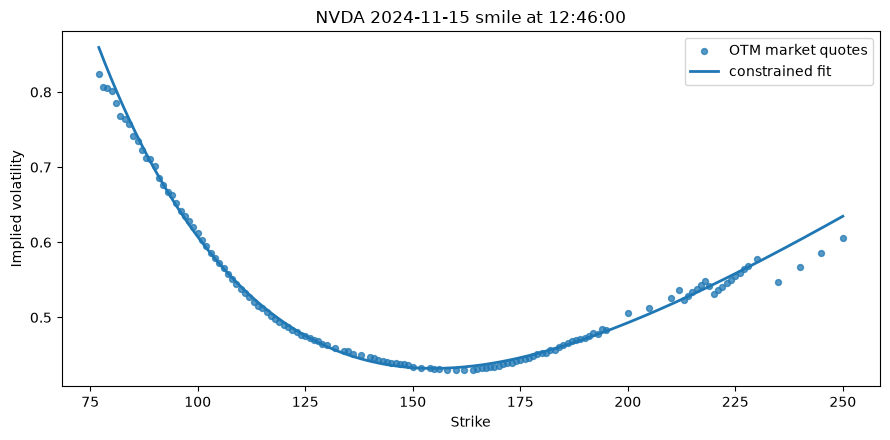

In [5]:
fits, snapshots, accepted_flags = [], [], []
prev = None
for j, (ts, g) in enumerate(quotes.groupby("timestamp", sort=True)):
    g = g.sort_values("strike").copy()
    F = float(g.forward.median())
    b, res, accepted, n_used = fit_curve(g.strike.to_numpy(float), g.mid.to_numpy(float), F, TAU, prev)
    prev = b
    fits.append(b); snapshots.append((ts, g, F)); accepted_flags.append(accepted)
    if (j + 1) % 50 == 0:
        print(f"Fitted {j + 1}/390 snapshots")
fits = np.asarray(fits)
dense_min = min(np.min(constraints(b, F, TAU, 201)) for b, (_, _, F) in zip(fits, snapshots))
assert len(fits) == 390 and dense_min >= -2e-5
print(f"Fitted {len(fits)} snapshots | optimizer accepted: {sum(accepted_flags)}/{len(fits)} | dense-grid minimum constraint: {dense_min:.3e}")

idx = len(snapshots) // 2
ts, g, F = snapshots[idx]
K = np.linspace(g.strike.min(), g.strike.max(), 250)
market_iv = [implied_vol(p, F, k, TAU, DF) for p, k in zip(g.mid, g.strike)]
fit_iv = np.sqrt(variance(fits[idx], np.log(K/F) / (np.sqrt(fits[idx, 0]) * np.sqrt(TAU))))
plt.figure(figsize=(9, 4.5))
plt.scatter(g.strike, market_iv, label="OTM market quotes", s=18, alpha=.75)
plt.plot(K, fit_iv, label="constrained fit", linewidth=2)
plt.xlabel("Strike"); plt.ylabel("Implied volatility")
plt.title(f"NVDA {EXPIRY.date()} smile at {ts.time()}")
plt.legend(); plt.tight_layout(); plt.show()

## 6. Independent numerical checks: endpoint slope and call arbitrage
Check the chain rule by finite differences, and test price monotonicity/convexity on a **denser grid than the optimization grid**. The constraints hold only over the specified SNS strike range; extrapolation is intentionally excluded.

In [6]:
idx = len(fits) // 2
b = fits[idx]; F = snapshots[idx][2]; a = np.sqrt(b[0]); s = np.linspace(-3.5, 3.5, 501)
K = F * np.exp(s * a * np.sqrt(TAU)); p = smile_prices(b, F, K, TAU, 1.0)
slope = np.diff(p) / np.diff(K)
assert np.min(slope) >= -1 - 2e-3 and np.max(slope) <= 2e-3
assert np.min(np.diff(slope)) >= -2e-5
assert np.max(np.abs(dbasis(s) @ b)) <= 2 * a / np.sqrt(TAU) + 1e-6
s_test, h = 1.2, 1e-5
k_test = s_test * a * np.sqrt(TAU)
num = (TAU * variance(b, (k_test+h)/(a*np.sqrt(TAU))) - TAU * variance(b, (k_test-h)/(a*np.sqrt(TAU)))) / (2*h)
analytic = np.dot(dbasis(s_test), b) * np.sqrt(TAU) / a
assert abs(num - analytic) < 1e-7
print("Dense-grid call monotonicity/convexity and endogenous Lee bound: PASS")
print(f"Slope range: [{slope.min():.6f}, {slope.max():.6f}] | min convexity increment: {np.diff(slope).min():.3e}")
print("Chain-rule finite-difference error:", abs(num - analytic))

Dense-grid call monotonicity/convexity and endogenous Lee bound: PASS
Slope range: [-0.993639, -0.000726] | min convexity increment: 1.980e-05
Chain-rule finite-difference error: 6.719711592717559e-13


## 7. One-step-ahead out-of-sample quote evaluation
Use the previous snapshot's fitted variance coefficients with the **next** snapshot's spot/forward; do not refit using future observations. Report percentage outside the spread, price MSE and signed bias. These are market-price metrics, not variance-fit losses.

In [7]:
errors, outside = [], []
for i in range(1, len(snapshots)):
    ts, g, F = snapshots[i]
    K = g.strike.to_numpy(float)
    pred = smile_prices(fits[i-1], F, K, TAU, DF)
    actual = g.mid.to_numpy(float)
    errors.extend(pred - actual)
    outside.extend((pred < g.bid.to_numpy(float)) | (pred > g.ask.to_numpy(float)))
errors = np.asarray(errors); outside = np.asarray(outside, dtype=bool)
metrics = {"observations": len(errors), "out_of_spread_pct": 100*np.mean(outside),
           "price_mse": np.mean(errors**2), "price_rmse": np.sqrt(np.mean(errors**2)),
           "price_bias": np.mean(errors)}
assert np.isfinite(list(metrics.values())).all()
print(pd.Series(metrics, name="1-minute-ahead — " + SOURCE).to_string())

observations         52072.000000
out_of_spread_pct       55.317637
price_mse                0.000548
price_rmse               0.023416
price_bias              -0.000334


## 8. Part 2(A): constrained Kalman filter
State $x_t=eta_t$, transition $x_t=x_{t-1}+\epsilon_t$, observations $y_t=B(s_t)x_t+\eta_t$ where $y_t$ is **observed annualized implied variance**. For fixed observation coordinates $s_t$, the textbook unconstrained update is $m^+=m^-+PH^T(HPH^T+R)^{-1}(y-Hm^-)$ and $P^+=(I-KH)P^-$. The constrained update projects the unconstrained posterior mean in the $P^{+^{-1}}$ metric onto the no-arbitrage feasible set. Because the SNS coordinate itself depends on the state ATM level, the observation coordinates are frozen at the predicted ATM each step (local linearization). The resulting procedure is an approximate constrained extended filter, not an exact linear Kalman filter.

In [8]:
def kalman_update(m, P, H, y, Rmat):
    S = H @ P @ H.T + Rmat
    Kg = np.linalg.solve(S, H @ P).T
    newm = m + Kg @ (y - H @ m)
    newP = (np.eye(len(m)) - Kg @ H) @ P
    return newm, (newP + newP.T) / 2

def project_posterior(mu, P, F, tau, feasible_start, loose=False):
    if loose:
        return mu.copy(), True
    precision = np.linalg.inv(P + 1e-10*np.eye(len(mu)))
    objective = lambda b: 0.5 * (b-mu) @ precision @ (b-mu)
    res = minimize(objective, feasible_start, method="SLSQP",
        bounds=[(0.02, 1.50)] + [(-2.0, 2.0)]*4,
        constraints=[{"type": "ineq", "fun": lambda b: constraints(b, F, tau, 41)}],
        options={"maxiter": 120, "ftol": 1e-9})
    ok = np.min(constraints(res.x, F, tau, 101)) >= -2e-5
    return (res.x if ok else feasible_start.copy()), ok

Qmat = np.diag([2e-5, 4e-6, 2e-6, 5e-7, 2e-7])
Robs = 0.004**2
m = fits[0].copy(); P = np.diag([2e-3, 5e-4, 2e-4, 5e-5, 2e-5])
filtered, projection_ok = [m.copy()], []
for i in range(1, len(snapshots)):
    ts, g, F = snapshots[i]; K = g.strike.to_numpy(float)
    iv = np.array([implied_vol(p, F, k, TAU, DF) for p, k in zip(g.mid, K)])
    valid = np.isfinite(iv) & (np.abs(np.log(K/F)/(np.sqrt(m[0])*np.sqrt(TAU))) <= 3.5)
    s_obs = np.log(K[valid]/F)/(np.sqrt(m[0])*np.sqrt(TAU))
    H = basis(s_obs); y = iv[valid]**2
    P = P + Qmat
    post, P = kalman_update(m, P, H, y, np.eye(len(y))*Robs)
    m, ok = project_posterior(post, P, F, TAU, fits[i])
    filtered.append(m.copy()); projection_ok.append(ok)
filtered = np.asarray(filtered)

# Required validation: with constraints made slack, projection is exactly the textbook posterior.
i = 10; _, g, F = snapshots[i]; K = g.strike.to_numpy(float)
iv = np.array([implied_vol(p, F, k, TAU, DF) for p, k in zip(g.mid, K)])
valid = np.isfinite(iv); H = basis(np.log(K[valid]/F)/(np.sqrt(fits[i-1,0])*np.sqrt(TAU))); y = iv[valid]**2
post_textbook, _ = kalman_update(fits[i-1], np.eye(5)*1e-3, H, y, np.eye(len(y))*Robs)
post_slack, _ = project_posterior(post_textbook, np.eye(5)*1e-3, F, TAU, fits[i], loose=True)
identity_error = np.max(np.abs(post_slack - post_textbook))
assert identity_error < 1e-12
print(f"Slack-constraint Kalman == textbook posterior: PASS (max error {identity_error:.1e})")
print(f"Successful constrained projections: {sum(projection_ok)}/{len(projection_ok)}")

Slack-constraint Kalman == textbook posterior: PASS (max error 0.0e+00)
Successful constrained projections: 389/389


## 9. Compare raw ATM, Kalman ATM, and exponential moving average; ACF
The EMA baseline uses smoothing weight 0.2. ACF curves quantify persistence, not necessarily forecast quality; compare with held-out quote errors before claiming one method is superior.

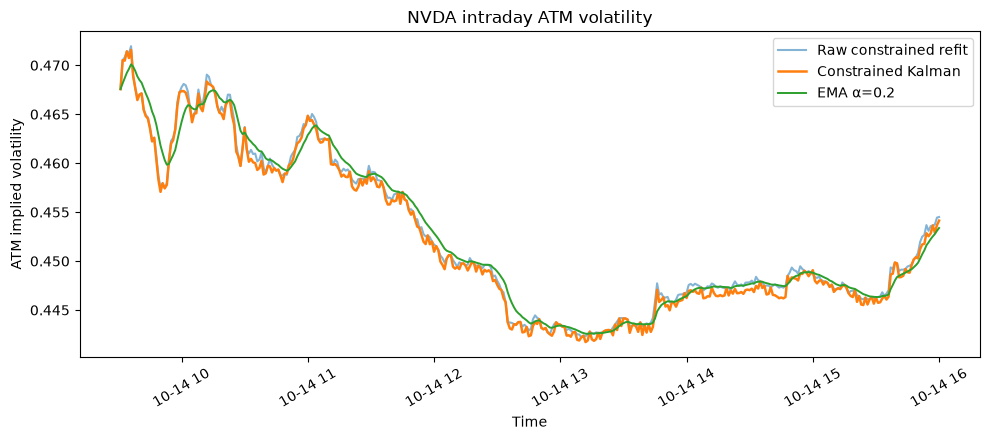

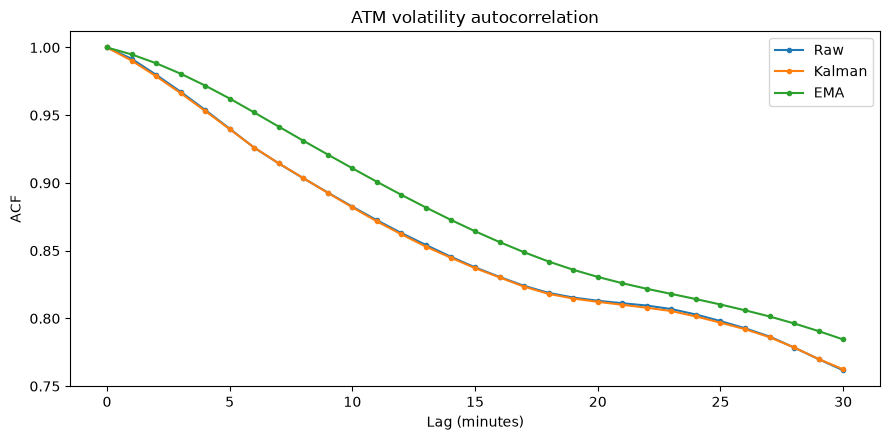

         raw_ATM  kalman_ATM    ema_ATM
count  390.00000   390.00000  390.00000
mean     0.45248     0.45208    0.45263
std      0.00796     0.00799    0.00800
min      0.44222     0.44173    0.44257
25%      0.44671     0.44623    0.44663
50%      0.44935     0.44885    0.44894
75%      0.45924     0.45894    0.45994
max      0.47196     0.47157    0.47010

Selected ACF values:
       Raw  Kalman     EMA
1   0.9917  0.9904  0.9949
5   0.9400  0.9397  0.9623
15  0.8377  0.8371  0.8643
30  0.7617  0.7624  0.7845


In [9]:
raw_atm = np.sqrt(fits[:, 0]); kalman_atm = np.sqrt(filtered[:, 0])
ema_atm = pd.Series(raw_atm).ewm(alpha=.2, adjust=False).mean().to_numpy()
times = [ts for ts, _, _ in snapshots]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(times, raw_atm, label="Raw constrained refit", alpha=.55)
ax.plot(times, kalman_atm, label="Constrained Kalman", linewidth=1.8)
ax.plot(times, ema_atm, label="EMA α=0.2", linewidth=1.4)
ax.set(xlabel="Time", ylabel="ATM implied volatility", title="NVDA intraday ATM volatility")
ax.legend(); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

lag = 30
plt.figure(figsize=(9, 4.5))
acf_table = {}
for label, series in [("Raw", raw_atm), ("Kalman", kalman_atm), ("EMA", ema_atm)]:
    values = acf(series, nlags=lag, fft=False); acf_table[label] = values
    plt.plot(np.arange(lag+1), values, marker="o", markersize=3, label=label)
plt.xlabel("Lag (minutes)"); plt.ylabel("ACF")
plt.title("ATM volatility autocorrelation"); plt.legend(); plt.tight_layout(); plt.show()
summary = pd.DataFrame({"raw_ATM": raw_atm, "kalman_ATM": kalman_atm, "ema_ATM": ema_atm}).describe().round(5)
print(summary)
print("\nSelected ACF values:")
print(pd.DataFrame(acf_table, index=np.arange(lag+1)).loc[[1, 5, 15, 30]].round(4))

## 10. Findings, market-making trade-offs, and limitations
**Real-data result:** the notebook fits all 390 one-minute snapshots for NVDA's 2024-11-15 expiry, using robust parity-implied forwards and OTM option quotes. The printed diagnostics above are the authoritative run results: optimizer acceptance/fallback count, dense-grid constraint minimum, one-minute-ahead spread/MSE/bias, Kalman projection success, ATM summary statistics, and ACF at 1/5/15/30 minutes.

**What temporal smoothing buys:** the constrained Kalman series suppresses microstructure-driven coefficient and Greek jitter while preserving the fitted curve's static-arbitrage conditions. For a market maker this supports steadier quotes, hedges, and inventory marks. Compared with an EMA, the filter uses the whole smile and observation/state uncertainty rather than smoothing ATM alone.

**Costs and limitations:** covariance calibration and constrained projections add computation and model risk; smoothing can lag jumps; freezing SNS observation coordinates at the predicted ATM is an extended-filter approximation; the projected covariance is not recomputed for the active constraint set. NVDA options are American, so European parity/Black–Scholes treatment is an approximation even though choosing OTM options and a short expiry reduces early-exercise effects. The rate is a short-dated proxy, and polynomial wings are intentionally not extrapolated beyond ±3.5 SNS. No-arbitrage is enforced and independently tested on dense finite grids, not proven between every pair of grid points.